In [4]:
import pandas as pd
import numpy as np
from sklearn.preprocessing import MinMaxScaler

In [5]:
# --- 1. Configuration ---
REAL_DATA_PATH = '../../../../data/data_with_features.csv'
SYNTHETIC_DATA_PATH = '../../../../data/syntheticData/synthetic_data_sarima_statsmodels.csv'
TARGET_COLUMN = 'cumulative_mite_count'
GROUP_COLUMN = 'treatment_id'

# Define the chronological split for your REAL data
TRAIN_RATIO = 0.8
VALIDATION_RATIO = 0.1
# The rest will be the TEST_RATIO (1.0 - 0.8 - 0.1 = 0.1)

In [6]:
# --- 2. Feature Engineering Function ---
print("--- Defining Feature Engineering Function ---")
def create_features(df):
    """Creates time-series features from a dataframe in a group-aware manner."""
    df = df.copy()
    df['observation_date'] = pd.to_datetime(df['observation_date'])
    df = df.sort_values(by=[GROUP_COLUMN, 'observation_date'])

    # Time-based features
    df['dayofweek'] = df['observation_date'].dt.dayofweek
    df['month'] = df['observation_date'].dt.month
    df['weekofyear'] = df['observation_date'].dt.isocalendar().week.astype(int)
    
    # Lag features (shifted within each group)
    df['lag_1'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(1)
    df['lag_3'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(3)
    df['lag_7'] = df.groupby(GROUP_COLUMN)[TARGET_COLUMN].shift(7)
    
    # Rolling window features
    df['rolling_mean_7'] = df.groupby(GROUP_COLUMN)['lag_1'].rolling(window=7, min_periods=1).mean().reset_index(drop=True)
    df['rolling_std_7'] = df.groupby(GROUP_COLUMN)['lag_1'].rolling(window=7, min_periods=1).std().reset_index(drop=True)
    
    # Drop the initial rows with NaNs created by the largest lag
    df = df.dropna()
    return df

--- Defining Feature Engineering Function ---


In [7]:
# --- 3. Process Real and Synthetic Data ---
print("\n--- Processing Datasets ---")
# Load and process REAL data
real_df = pd.read_csv(REAL_DATA_PATH)
real_featured_df = create_features(real_df)
print(f"   Real data features created. Shape after dropping NaNs: {real_featured_df.shape}")

# Load and process SYNTHETIC data
synthetic_df = pd.read_csv(SYNTHETIC_DATA_PATH)
# Create unique IDs for synthetic data BEFORE feature engineering
synthetic_df[GROUP_COLUMN] = synthetic_df[GROUP_COLUMN].astype(str) + '_synth'
synthetic_featured_df = create_features(synthetic_df)
print(f"   Synthetic data features created. Shape after dropping NaNs: {synthetic_featured_df.shape}")


--- Processing Datasets ---
   Real data features created. Shape after dropping NaNs: (2083, 22)
   Synthetic data features created. Shape after dropping NaNs: (2189, 22)


In [8]:
# --- 4. Chronological Split (on feature-engineered REAL data) ---
print("\n--- Splitting Real Data into Train, Validation, and Test Sets ---")
train_real_list, val_real_list, test_real_list = [], [], []

for group_id, group_df in real_featured_df.groupby(GROUP_COLUMN):
    n_rows = len(group_df)
    train_end = int(n_rows * TRAIN_RATIO)
    val_end = int(n_rows * (TRAIN_RATIO + VALIDATION_RATIO))
    
    train_real_list.append(group_df.iloc[:train_end])
    val_real_list.append(group_df.iloc[train_end:val_end])
    test_real_list.append(group_df.iloc[val_end:])

train_real_df = pd.concat(train_real_list)
val_df = pd.concat(val_real_list)
test_df = pd.concat(test_real_list)


--- Splitting Real Data into Train, Validation, and Test Sets ---


In [9]:
# --- 5. Create Augmented Training Set ---
print("\n--- Creating Augmented Training Set (Real + Synthetic) ---")
train_ids = train_real_df[GROUP_COLUMN].unique()
# The synthetic group IDs already have the '_synth' suffix
synthetic_train_ids = [str(tid) + '_synth' for tid in train_ids]
synthetic_train_df = synthetic_featured_df[synthetic_featured_df[GROUP_COLUMN].isin(synthetic_train_ids)]

augmented_df = pd.concat([train_real_df, synthetic_train_df], ignore_index=True)
print(f"   Augmented Training Set Shape: {augmented_df.shape}")


--- Creating Augmented Training Set (Real + Synthetic) ---
   Augmented Training Set Shape: (3750, 22)


In [10]:
# --- 6. Final Preparation for Modeling ---
print("\n--- Finalizing Data for Feature-Based Models ---")
features_to_use = [
    'dayofweek', 'month', 'weekofyear', 'lag_1', 'lag_3', 'lag_7',
    'rolling_mean_7', 'rolling_std_7', 'initial_female_count', 'leaf_area_cm2',
    'population_density', 'initial_growth_potential'
]

X_train = augmented_df[features_to_use]
y_train = augmented_df[TARGET_COLUMN]

X_val = val_df[features_to_use]
y_val = val_df[TARGET_COLUMN]

X_test = test_df[features_to_use]
y_test = test_df[TARGET_COLUMN]

# Scale the feature data
scaler = MinMaxScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

print(f"\n   Data is now ready for training.")
print(f"   X_train shape: {X_train_scaled.shape}, y_train shape: {y_train.shape}")
print(f"   X_val shape:   {X_val_scaled.shape}, y_val shape: {y_val.shape}")
print(f"   X_test shape:  {X_test_scaled.shape}, y_test shape: {y_test.shape}")


--- Finalizing Data for Feature-Based Models ---

   Data is now ready for training.
   X_train shape: (3750, 12), y_train shape: (3750,)
   X_val shape:   (202, 12), y_val shape: (202,)
   X_test shape:  (305, 12), y_test shape: (305,)


In [11]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, mean_absolute_error,r2_score,root_mean_squared_error
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

# --- 1. Train the XGBoost Model ---

# Initialize the XGBoost Regressor with some strong default parameters
xgb_model = xgb.XGBRegressor(
    n_estimators=100,         # Number of trees to build
    learning_rate=0.05,        # How quickly the model learns
    objective='reg:squarederror',
    eval_metric='rmse',
    early_stopping_rounds=50,  # Stop training if validation score doesn't improve for 50 rounds
    n_jobs=-1                  # Use all available CPU cores
)

print("   Training XGBoost model... This may take a moment.")
# Fit the model on the training data, using the validation data to prevent overfitting
xgb_model.fit(X_train_scaled, y_train,
              eval_set=[(X_val_scaled, y_val)],
              verbose=False)

print("   Model training complete.")


# --- 2. Evaluate Performance on Validation Set ---
print("\n--- Evaluating XGBoost performance on VALIDATION set ---")

# Predict on the validation set
val_predictions = xgb_model.predict(X_val_scaled)

# Calculate metrics for single-step predictions
rmse_val = root_mean_squared_error(y_val, val_predictions)
mse_val = mean_squared_error(y_val, val_predictions)
mae_val = mean_absolute_error(y_val, val_predictions)
r2 = r2_score(y_val, val_predictions)

# Calculate metrics for single-step predictions training
rmse_train = root_mean_squared_error(y_train, xgb_model.predict(X_train_scaled))
mse_train = mean_squared_error(y_train, xgb_model.predict(X_train_scaled))
mae_train = mean_absolute_error(y_train, xgb_model.predict(X_train_scaled))
r2_train = r2_score(y_train, xgb_model.predict(X_train_scaled))

print(f"\n   XGBoost Validation RMSE: {rmse_val:.4f}")
print(f"   XGBoost Validation MSE: {mse_val:.4f}")
print(f"   XGBoost Validation MAE:  {mae_val:.4f}")
print(f"   XGBoost Validation R^2:  {r2:.4f}")

print(f"\n   XGBoost Training RMSE: {rmse_train:.4f}")
print(f"   XGBoost Training MSE: {mse_train:.4f}")
print(f"   XGBoost Training MAE:  {mae_train:.4f}")
print(f"   XGBoost Training R^2:  {r2_train:.4f}")

   Training XGBoost model... This may take a moment.
   Model training complete.

--- Evaluating XGBoost performance on VALIDATION set ---

   XGBoost Validation RMSE: 3.9062
   XGBoost Validation MSE: 15.2586
   XGBoost Validation MAE:  2.9419
   XGBoost Validation R^2:  0.9994

   XGBoost Training RMSE: 5.3904
   XGBoost Training MSE: 29.0565
   XGBoost Training MAE:  3.5901
   XGBoost Training R^2:  0.9987


In [12]:
import xgboost as xgb
from sklearn.metrics import mean_squared_error, r2_score, root_mean_squared_error
import warnings

warnings.filterwarnings("ignore", category=UserWarning)

# --- 1. Train the XGBoost Model with Anti-Overfitting Parameters ---

# Initialize the XGBoost Regressor with parameters to control complexity
xgb_model = xgb.XGBRegressor(
    # Core Parameters
    n_estimators=1000,             # Increased: Give early stopping more room to find the best tree count
    learning_rate=0.05,            # A small learning rate is good for generalization
    objective='reg:squarederror',
    eval_metric='rmse',
    early_stopping_rounds=50,      # Your original, correct use of early stopping

    # Parameters to Control Overfitting
    max_depth=4,                   # Lowered: Prevents individual trees from becoming too complex (default is 6)
    subsample=0.8,                 # Use 80% of data for training each tree (stochasticity)
    colsample_bytree=0.8,          # Use 80% of features for training each tree (stochasticity)
    gamma=0.1,                     # Minimum loss reduction to make a split (pruning)
    reg_lambda=1,                  # L2 regularization term (smooths weights)

    # Performance
    n_jobs=-1                      # Use all available CPU cores
)

print("   Training XGBoost model with anti-overfitting parameters...")
# Fit the model on the training data, using the validation data to prevent overfitting
xgb_model.fit(X_train_scaled, y_train,
              eval_set=[(X_val_scaled, y_val)],
              verbose=False)

print(f"   Model training complete. Optimal number of trees: {xgb_model.best_iteration}")

# --- 2. Evaluate Performance on Validation Set ---
print("\n--- Evaluating XGBoost performance on VALIDATION set ---")

# Predict on the validation and training sets
val_predictions = xgb_model.predict(X_val_scaled)
train_predictions = xgb_model.predict(X_train_scaled)

# Calculate metrics for the validation set
rmse_val = root_mean_squared_error(y_val, val_predictions)
mae_val = mean_absolute_error(y_val, val_predictions)
mse_val = mean_squared_error(y_val, val_predictions)
r2_val = r2_score(y_val, val_predictions)

# Calculate metrics for the training set
rmse_train = root_mean_squared_error(y_train, train_predictions)
mae_train = mean_absolute_error(y_train, train_predictions)
mse_train = mean_squared_error(y_train, train_predictions)
r2_train = r2_score(y_train, train_predictions)

print(f"\n   XGBoost Validation RMSE: {rmse_val:.4f}")
print(f"   XGBoost Validation MAE:  {mae_val:.4f}")
print(f"   XGBoost Validation MSE:  {mse_val:.4f}")
print(f"   XGBoost Validation R^2:  {r2_val:.4f}")

print(f"\n   XGBoost Training RMSE: {rmse_train:.4f}")
print(f"   XGBoost Training MAE:  {mae_train:.4f}")
print(f"   XGBoost Training MSE:  {mse_train:.4f}")
print(f"   XGBoost Training R^2:  {r2_train:.4f}")

   Training XGBoost model with anti-overfitting parameters...
   Model training complete. Optimal number of trees: 625

--- Evaluating XGBoost performance on VALIDATION set ---

   XGBoost Validation RMSE: 4.5976
   XGBoost Validation MAE:  3.3220
   XGBoost Validation MSE:  21.1384
   XGBoost Validation R^2:  0.9992

   XGBoost Training RMSE: 4.3753
   XGBoost Training MAE:  3.0694
   XGBoost Training MSE:  19.1429
   XGBoost Training R^2:  0.9991


In [13]:
import pandas as pd
import numpy as np
from datetime import timedelta

def forecast_experiment(initial_females, leaf_area, model, num_days=15):
    """
    Generates a forecast using an autoregressive loop with an unscaled model.

    Args:
        initial_females (int): The starting number of female mites.
        leaf_area (float): The leaf area in cm².
        model (xgb.XGBRegressor): The trained XGBoost model.
        num_days (int): The number of days to forecast.

    Returns:
        numpy.ndarray: An array containing the 15-day forecast of mite counts.
    """
    print(f"\n--- Generating {num_days}-day forecast for initial conditions: ---")
    print(f"   Initial Female Count: {initial_females}")
    print(f"   Leaf Area (cm²): {leaf_area}")

    # Get the feature names in the exact order the model expects
    feature_columns = model.get_booster().feature_names

    # This history will store predictions to build future features.
    # Start with a buffer of zeros to handle the longest lag (lag_7).
    history = [0] * 7
    
    predictions = []
    start_date = pd.to_datetime('today') # Use current date as a starting point

    for day_num in range(1, num_days + 1):
        # --- 1. Create the feature set for the current day ---
        # Create a DataFrame with the correct column order
        current_features = pd.DataFrame(columns=feature_columns)
        
        # a) Populate initial (static) features
        current_features.loc[0, 'initial_female_count'] = initial_females
        current_features.loc[0, 'leaf_area_cm2'] = leaf_area
        if leaf_area > 0:
            current_features.loc[0, 'population_density'] = initial_females / leaf_area
        current_features.loc[0, 'initial_growth_potential'] = initial_females * leaf_area

        # b) Populate time-based (dynamic) features
        current_date = start_date + timedelta(days=day_num - 1)
        current_features.loc[0, 'dayofweek'] = current_date.dayofweek
        current_features.loc[0, 'month'] = current_date.month
        current_features.loc[0, 'weekofyear'] = current_date.isocalendar().week

        # c) Populate historical (autoregressive) features from the 'history' list
        current_features.loc[0, 'lag_1'] = history[-1]
        current_features.loc[0, 'lag_3'] = history[-3]
        current_features.loc[0, 'lag_7'] = history[-7]
        
        rolling_hist = pd.Series(history)
        current_features.loc[0, 'rolling_mean_7'] = rolling_hist.iloc[-7:].mean()
        current_features.loc[0, 'rolling_std_7'] = rolling_hist.iloc[-7:].std()
        
        # Fill NaN values (e.g., for standard deviation at the beginning) with 0
        current_features = current_features.fillna(0)

        # --- 2. Predict ---
        # No scaling is needed. Predict directly on the created features.
        prediction = model.predict(current_features)[0]
        
        # --- 3. Store the result and update history ---
        # Enforce non-negativity: the mite count cannot be less than zero
        prediction = max(0, prediction)
        
        predictions.append(prediction)
        history.append(prediction) # Add the new prediction to history for the next loop
            
    return np.array(predictions)


--- Generating 15-day forecast for initial conditions: ---
   Initial Female Count: 1
   Leaf Area (cm²): 60

--- Forecasted Cumulative Mite Count ---
    Day  Predicted_Count
0     1              616
1     2              637
2     3              637
3     4              641
4     5              641
5     6              519
6     7              641
7     8              640
8     9              640
9    10              640
10   11              640
11   12              640
12   13              521
13   14              640
14   15              640


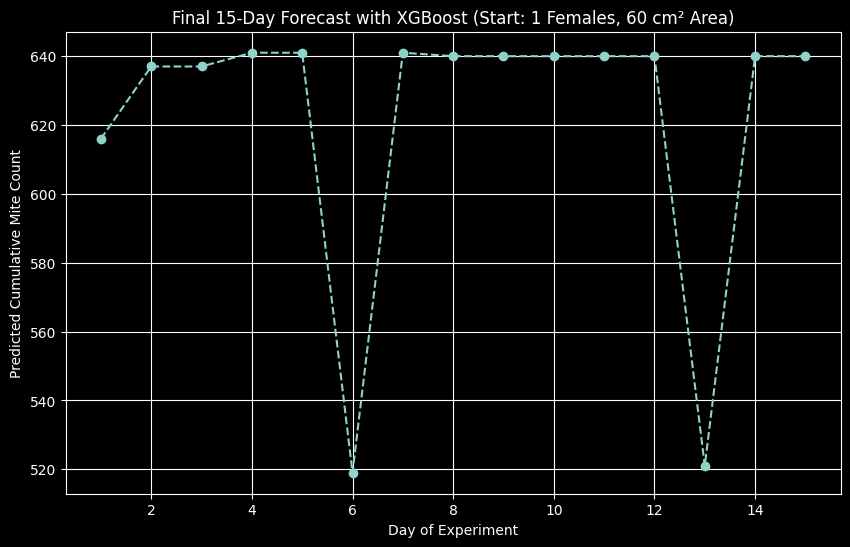

In [19]:
import matplotlib.pyplot as plt
# --- 3. Run the Final Application ---
initial_female_input = 1
leaf_area_input = 60

forecast = forecast_experiment(
    initial_females=initial_female_input,
    leaf_area=leaf_area_input,
    model=xgb_model, # Your trained model
    num_days=15
)

# --- 4. Display the Final Results ---
print("\n--- Forecasted Cumulative Mite Count ---")
day_by_day_forecast = pd.DataFrame({
    'Day': np.arange(1, 16),
    'Predicted_Count': forecast
})

# Round to the nearest whole number for a realistic count
day_by_day_forecast['Predicted_Count'] = day_by_day_forecast['Predicted_Count'].round(0).astype(int)
print(day_by_day_forecast)

# Plot the forecast
plt.figure(figsize=(10, 6))
plt.plot(day_by_day_forecast['Day'], day_by_day_forecast['Predicted_Count'], marker='o', linestyle='--')
plt.title(f'Final 15-Day Forecast with XGBoost (Start: {initial_female_input} Females, {leaf_area_input} cm² Area)')
plt.xlabel("Day of Experiment")
plt.ylabel("Predicted Cumulative Mite Count")
plt.grid(True)
plt.show()